# N-BaIoT Ablation 1: CNN + Transformer Only (No BiLSTM)

Removes the **BiLSTM** component. CNN output → Transformer → GlobalAvgPool → Classifier.

In [2]:
!pip install torch pandas numpy scikit-learn matplotlib seaborn tqdm --quiet

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import math
import time
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import confusion_matrix, classification_report, f1_score, accuracy_score, precision_score, recall_score
from sklearn.neighbors import NearestNeighbors
from tqdm import tqdm

np.random.seed(42)
torch.manual_seed(42)

# ── Device: safe for Kaggle T4 / any GPU ──────────────────
if torch.cuda.is_available():
    try:
        _ = torch.zeros(1).cuda()
        device = torch.device("cuda")
        print(f"GPU: {torch.cuda.get_device_name(0)}")
    except Exception as e:
        print(f"GPU failed ({e}), using CPU.")
        device = torch.device("cpu")
else:
    device = torch.device("cpu")
print(f"Device: {device}")

GPU: Tesla T4
Device: cuda


In [9]:
CONFIG = {
    'batch_size': 512,
    'epochs': 30,
    'learning_rate': 0.001,
    'input_shape': (115, 1),
    'dataset_paths': [
        "/kaggle/input/datasets/mkashifn/nbaiot-dataset/1.benign.csv",
        "/kaggle/input/datasets/mkashifn/nbaiot-dataset/1.gafgyt.combo.csv",
        "/kaggle/input/datasets/mkashifn/nbaiot-dataset/1.gafgyt.junk.csv",
        "/kaggle/input/datasets/mkashifn/nbaiot-dataset/1.gafgyt.tcp.csv",
        "/kaggle/input/datasets/mkashifn/nbaiot-dataset/1.mirai.udp.csv",
        "/kaggle/input/datasets/mkashifn/nbaiot-dataset/1.mirai.scan.csv",
        "/kaggle/input/datasets/mkashifn/nbaiot-dataset/1.mirai.syn.csv",
        "/kaggle/input/datasets/mkashifn/nbaiot-dataset/1.mirai.udpplain.csv",
        "/kaggle/input/datasets/mkashifn/nbaiot-dataset/1.mirai.ack.csv",
        # "/kaggle/input/datasets/mkashifn/nbaiot-dataset/2.benign.csv",
        # "/kaggle/input/datasets/mkashifn/nbaiot-dataset/2.gafgyt.combo.csv",
        # "/kaggle/input/datasets/mkashifn/nbaiot-dataset/2.gafgyt.junk.csv",
        # "/kaggle/input/datasets/mkashifn/nbaiot-dataset/2.gafgyt.tcp.csv",
        # "/kaggle/input/datasets/mkashifn/nbaiot-dataset/2.mirai.udp.csv",
        # "/kaggle/input/datasets/mkashifn/nbaiot-dataset/2.mirai.scan.csv",
        # "/kaggle/input/datasets/mkashifn/nbaiot-dataset/2.mirai.syn.csv",
        # "/kaggle/input/datasets/mkashifn/nbaiot-dataset/2.mirai.udpplain.csv",
        # "/kaggle/input/datasets/mkashifn/nbaiot-dataset/1.mirai.ack.csv",
    ],
    "labels": [
        "benign", "Gafgyt_Combo", "Gafgyt_Junk", "Gafgyt_TCP",
        "Mirai_UDP", "Mirai_Scan", "Mirai_SYN", "Mirai_UDPPlain", "Mirai_ACK",
    ],
}

SEEN_CLASSES   = ['Mirai_UDP','Mirai_SYN','Mirai_ACK','Gafgyt_TCP',
                  'Gafgyt_Combo','benign','Gafgyt_Junk','Mirai_UDPPlain']
UNSEEN_CLASSES = ['Mirai_Scan']

print(f"Seen   : {SEEN_CLASSES}")
print(f"Unseen : {UNSEEN_CLASSES}")

Seen   : ['Mirai_UDP', 'Mirai_SYN', 'Mirai_ACK', 'Gafgyt_TCP', 'Gafgyt_Combo', 'benign', 'Gafgyt_Junk', 'Mirai_UDPPlain']
Unseen : ['Mirai_Scan']


In [10]:
class IoTDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.long)
    def __len__(self):        return len(self.X)
    def __getitem__(self, i): return self.X[i], self.y[i]

# ── Load all CSVs ──────────────────────────────────────────
full_data = pd.DataFrame()
for i, path in enumerate(CONFIG["dataset_paths"]):
    df1 = pd.read_csv(path)
    df2 = pd.read_csv(path.replace("1", "2"))
    df1["label"] = CONFIG["labels"][i]
    df2["label"] = CONFIG["labels"][i]
    full_data = pd.concat([full_data, df1, df2], ignore_index=True)

print(f"Total rows: {len(full_data)}")
print(full_data["label"].value_counts())

# ── Features & labels ─────────────────────────────────────
X_raw = full_data.drop(["label"], axis=1).values.astype(np.float32)
y_raw = full_data["label"].values

# ── Seen / Unseen split ───────────────────────────────────
seen_mask   = np.isin(y_raw, SEEN_CLASSES)
unseen_mask = np.isin(y_raw, UNSEEN_CLASSES)

X_seen, y_seen     = X_raw[seen_mask],   y_raw[seen_mask]
X_unseen, y_unseen = X_raw[unseen_mask], y_raw[unseen_mask]

# ── Encode seen labels ────────────────────────────────────
le = LabelEncoder()
y_seen_enc = le.fit_transform(y_seen)
num_classes = len(le.classes_)

X_train, X_temp, y_train, y_temp = train_test_split(
    X_seen, y_seen_enc, test_size=0.3, random_state=42, stratify=y_seen_enc)
X_val, X_test_seen, y_val, y_test_seen = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp)

# ── Scale (fit on train only) ─────────────────────────────
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_val   = scaler.transform(X_val)
X_test_seen  = scaler.transform(X_test_seen)
X_unseen_sc  = scaler.transform(X_unseen)

# ── Build final test set (seen + unseen) ──────────────────
y_test_seen_str = le.inverse_transform(y_test_seen)
X_test_final    = np.concatenate([X_test_seen, X_unseen_sc], axis=0)
y_test_final_str= np.concatenate([y_test_seen_str, y_unseen], axis=0)

# ── Reshape to (N, Features, 1) ───────────────────────────
X_train_3d = X_train.reshape(X_train.shape[0], X_train.shape[1], 1)
X_val_3d   = X_val.reshape(X_val.shape[0], X_val.shape[1], 1)
X_test_3d  = X_test_final.reshape(X_test_final.shape[0], X_test_final.shape[1], 1)

y_test_dummy = np.zeros(len(X_test_3d), dtype=np.int64)

train_dataset = IoTDataset(X_train_3d, y_train)
val_dataset   = IoTDataset(X_val_3d,   y_val)
test_dataset  = IoTDataset(X_test_3d,  y_test_dummy)

# ── WeightedRandomSampler ─────────────────────────────────
class_counts     = np.bincount(y_train, minlength=num_classes)
class_weights_val= 1.0 / np.maximum(class_counts, 1)
sample_weights   = class_weights_val[y_train].astype(np.float64)
sampler = WeightedRandomSampler(weights=sample_weights, num_samples=len(sample_weights), replacement=True)

train_loader = DataLoader(train_dataset, batch_size=CONFIG['batch_size'], sampler=sampler,
                          shuffle=False, num_workers=4, pin_memory=True)
val_loader   = DataLoader(val_dataset,   batch_size=CONFIG['batch_size'],
                          shuffle=False, num_workers=4, pin_memory=True)
test_loader  = DataLoader(test_dataset,  batch_size=CONFIG['batch_size'],
                          shuffle=False, num_workers=4, pin_memory=True)

print(f"Train: {len(X_train)} | Val: {len(X_val)} | Test: {len(X_test_final)}")
print(f"Num classes: {num_classes} -> {list(le.classes_)}")

Total rows: 1586166
label
Mirai_UDP         389146
Mirai_SYN         239380
Mirai_ACK         215480
Gafgyt_TCP        187162
Mirai_UDPPlain    169350
Mirai_Scan        150877
Gafgyt_Combo      112730
benign             62661
Gafgyt_Junk        59380
Name: count, dtype: int64
Train: 1004702 | Val: 215293 | Test: 366171
Num classes: 8 -> ['Gafgyt_Combo', 'Gafgyt_Junk', 'Gafgyt_TCP', 'Mirai_ACK', 'Mirai_SYN', 'Mirai_UDP', 'Mirai_UDPPlain', 'benign']


In [11]:
def train_model(model, train_loader, val_loader, epochs, save_path):
    criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
    optimizer = optim.Adam(model.parameters(), lr=CONFIG['learning_rate'], weight_decay=1e-4)
    history = {'accuracy': [], 'val_accuracy': [], 'loss': [], 'val_loss': []}
    best_val_acc = 0.0

    for epoch in range(epochs):
        model.train()
        running_loss, correct, total = 0.0, 0, 0
        for inputs, labels in tqdm(train_loader, desc=f"Epoch {epoch+1}/{epochs}", leave=True):
            inputs, labels = inputs.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            running_loss += loss.item()
            _, predicted = torch.max(outputs.data, 1)
            total  += labels.size(0)
            correct += (predicted == labels).sum().item()

        epoch_acc  = correct / total
        epoch_loss = running_loss / len(train_loader)

        model.eval()
        val_loss, val_correct, val_total = 0.0, 0, 0
        with torch.no_grad():
            for inputs, labels in val_loader:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = model(inputs)
                val_loss    += criterion(outputs, labels).item()
                _, predicted = torch.max(outputs.data, 1)
                val_total   += labels.size(0)
                val_correct += (predicted == labels).sum().item()

        val_acc     = val_correct / val_total
        val_loss_avg= val_loss / len(val_loader)
        history['accuracy'].append(epoch_acc)
        history['loss'].append(epoch_loss)
        history['val_accuracy'].append(val_acc)
        history['val_loss'].append(val_loss_avg)

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            torch.save(model.state_dict(), save_path)
            print(f"  --> Best model saved (Val Acc: {val_acc:.4f})")
        print(f"Epoch {epoch+1}: Loss={epoch_loss:.4f} | Acc={epoch_acc:.4f} | ValLoss={val_loss_avg:.4f} | ValAcc={val_acc:.4f}")

    torch.save(model.state_dict(), save_path.replace('best', 'final'))
    return history

def plot_history(history, title):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
    ax1.plot(history['loss'],      label='Train Loss')
    ax1.plot(history['val_loss'],  label='Val Loss')
    ax1.set_title(f'{title} - Loss'); ax1.legend()
    ax2.plot(history['accuracy'],     label='Train Acc')
    ax2.plot(history['val_accuracy'], label='Val Acc')
    ax2.set_title(f'{title} - Accuracy'); ax2.legend()
    plt.tight_layout()
    plt.savefig(f'{title.replace(" ","_")}_training_curves.png', dpi=150)
    plt.show()

In [12]:
class MinMaxThreeWayGate:
    def __init__(self, q=60, eps=1e-12, dist_percentile=99):
        self.q = q; self.eps = eps; self.dist_percentile = dist_percentile

    def fit(self, X_train, y_train):
        self.X_train = np.asarray(X_train, dtype=np.float32)
        self.y_train = np.asarray(y_train)
        self.classes_ = np.unique(self.y_train)
        self.class_to_idx_ = {c: i for i, c in enumerate(self.classes_)}
        C = len(self.classes_)

        self.nn_train_ = NearestNeighbors(n_neighbors=self.q + 1, metric="euclidean")
        self.nn_train_.fit(self.X_train)
        neigh_idx_train = self.nn_train_.kneighbors(self.X_train, return_distance=False)[:, 1:]

        e_train = np.zeros((self.X_train.shape[0], C), dtype=np.float32)
        for i in range(self.X_train.shape[0]):
            for c in self.y_train[neigh_idx_train[i]]:
                e_train[i, self.class_to_idx_[c]] += 1.0
        e_train /= float(self.q)
        self.e_train_ = e_train

        dists_train  = self.nn_train_.kneighbors(self.X_train, return_distance=True)[0][:, 1:]
        self.dist_tau_ = np.percentile(dists_train.mean(axis=1), self.dist_percentile)

        self.nn_test_ = NearestNeighbors(n_neighbors=self.q, metric="euclidean")
        self.nn_test_.fit(self.X_train)
        return self

    def predict_region(self, X_test):
        X_test = np.asarray(X_test, dtype=np.float32)
        C = len(self.classes_)
        dists, neigh_idx = self.nn_test_.kneighbors(X_test, return_distance=True)

        e_test = np.zeros((X_test.shape[0], C), dtype=np.float32)
        for i in range(X_test.shape[0]):
            for c in self.y_train[neigh_idx[i]]:
                e_test[i, self.class_to_idx_[c]] += 1.0
        e_test /= float(self.q)

        best_k    = e_test.argmax(axis=1)
        best_class= self.classes_[best_k]
        conf      = e_test[np.arange(X_test.shape[0]), best_k]

        reduction = np.array([self.e_train_[neigh_idx[i]][:, best_k[i]].min() for i in range(X_test.shape[0])], dtype=np.float32)
        elevation = np.array([self.e_train_[neigh_idx[i]][:, best_k[i]].max() for i in range(X_test.shape[0])], dtype=np.float32)

        inside  = (reduction >= 1.0 - self.eps) & (conf >= 1.0 - self.eps)
        support = (elevation >= 1.0 - self.eps)
        region  = np.where(inside, "inside", np.where(support, "partial", "outside"))
        region  = np.where(dists.mean(axis=1) > self.dist_tau_, "outside", region)
        return best_class, region, conf

def get_prob_features(model, loader, device, temperature=1.0):
    model.eval()
    feats, labels = [], []
    with torch.no_grad():
        for inputs, y in loader:
            inputs = inputs.to(device)
            probs  = torch.softmax(model(inputs) / temperature, dim=1)
            feats.append(probs.cpu().numpy())
            labels.append(y.numpy())
    return np.concatenate(feats), np.concatenate(labels)

def predict_minmax_3labels(model, loader, gate, le, device, temperature=1.0):
    model.eval()
    preds = []
    with torch.no_grad():
        for inputs, _ in loader:
            inputs = inputs.to(device)
            probs  = torch.softmax(model(inputs) / temperature, dim=1).cpu().numpy()
            best_class_idx, region, _ = gate.predict_region(probs)
            for k_idx, r in zip(best_class_idx, region):
                preds.append(le.inverse_transform([k_idx])[0] if r == "inside" else "Emerging")
    return np.array(preds)

In [13]:
def evaluate_model(model, test_loader, gate, le, y_test_final_str, model_name):
    print(f"\n{'='*60}")
    print(f"  EVALUATION: {model_name}")
    print(f"{'='*60}")

    y_pred = predict_minmax_3labels(model, test_loader, gate, le, device, temperature=1.0)

    # ── Exclude 'Emerging' from metrics and confusion matrix ────────
    mask = (np.array(y_pred) != "Emerging") & (np.array(y_test_final_str) != "Emerging")
    y_true_f = np.array(y_test_final_str)[mask]
    y_pred_f = np.array(y_pred)[mask]

    print(f"\n  Total test samples  : {len(y_test_final_str)}")
    print(f"  Predicted Emerging  : {int((np.array(y_pred)=='Emerging').sum())} (excluded from metrics)")
    print(f"  Evaluated samples   : {int(mask.sum())}")

    all_classes = sorted(list(set(y_true_f) | set(y_pred_f)))

    acc  = accuracy_score(y_true_f, y_pred_f)
    prec = precision_score(y_true_f, y_pred_f, average='weighted', zero_division=0)
    rec  = recall_score(y_true_f, y_pred_f, average='weighted', zero_division=0)
    f1   = f1_score(y_true_f, y_pred_f, average='weighted', zero_division=0)

    print(f"\n  Accuracy : {acc:.4f}")
    print(f"  Precision: {prec:.4f}")
    print(f"  Recall   : {rec:.4f}")
    print(f"  F1-Score : {f1:.4f}")
    print("\n  Classification Report (Emerging excluded):")
    print(classification_report(y_true_f, y_pred_f, zero_division=0))

    # Confusion Matrix
    cm = confusion_matrix(y_true_f, y_pred_f, labels=all_classes)
    plt.figure(figsize=(10, 8))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=all_classes, yticklabels=all_classes)
    plt.title(f'Confusion Matrix - {model_name}\n(Emerging excluded)')
    plt.ylabel('True Label'); plt.xlabel('Predicted Label')
    plt.xticks(rotation=45, ha='right'); plt.yticks(rotation=0)
    plt.tight_layout()
    plt.savefig(f'{model_name.replace(" ","_")}_confusion_matrix.png', dpi=150)
    plt.show()

    return {'model': model_name, 'accuracy': acc, 'precision': prec, 'recall': rec, 'f1': f1}

In [14]:
# ============================================================
# ABLATION 1: CNN + Transformer Only  (No BiLSTM)
# Identical to full model except BiLSTM is replaced by
# Global Average Pooling over the Transformer output.
# ============================================================

class SinusoidalPositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=5000, dropout=0.1):
        super().__init__()
        self.dropout = nn.Dropout(dropout)
        pe = torch.zeros(max_len, d_model)
        pos = torch.arange(0, max_len, dtype=torch.float).unsqueeze(1)
        div = torch.exp(torch.arange(0, d_model, 2, dtype=torch.float) * (-math.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(pos * div)
        pe[:, 1::2] = torch.cos(pos * div)
        self.register_buffer("pe", pe.unsqueeze(0))
    def forward(self, x):
        x = x + self.pe[:, :x.size(1), :]
        return self.dropout(x)


class CNNTransformerOnly(nn.Module):
    """
    Ablation: Removes BiLSTM.
    CNN -> Positional Encoding -> Transformer -> GlobalAvgPool -> Classifier
    """
    def __init__(self, input_len, num_classes):
        super().__init__()
        # CNN  (same as full model)
        self.conv1   = nn.Conv1d(1,   128, kernel_size=3, padding=1)
        self.relu    = nn.ReLU()
        self.pool    = nn.MaxPool1d(kernel_size=2)
        self.conv2   = nn.Conv1d(128, 256, kernel_size=3, padding=1)
        # Positional encoding
        self.pos_enc = SinusoidalPositionalEncoding(256, max_len=max(1, input_len//2), dropout=0.1)
        # Transformer  (same as full model)
        enc_layer    = nn.TransformerEncoderLayer(d_model=256, nhead=4, dim_feedforward=256,
                                                   dropout=0.1, batch_first=True)
        self.transformer = nn.TransformerEncoder(enc_layer, num_layers=1)
        # Global Avg Pool  replaces BiLSTM
        self.gap     = nn.AdaptiveAvgPool1d(1)
        # Classifier
        self.fc1     = nn.Linear(256, 64)
        self.dropout = nn.Dropout(0.3)
        self.fc_out  = nn.Linear(64, num_classes)

    def forward(self, x):
        x = x.permute(0, 2, 1)           # (B,1,F)
        x = self.relu(self.conv1(x))      # (B,128,F)
        x = self.pool(x)                  # (B,128,F/2)
        x = self.relu(self.conv2(x))      # (B,256,F/2)
        x = x.permute(0, 2, 1)           # (B,F/2,256)
        x = self.pos_enc(x)
        x = self.transformer(x)           # (B,F/2,256)
        x = x.permute(0, 2, 1)           # (B,256,F/2)
        x = self.gap(x).squeeze(-1)       # (B,256)
        x = self.relu(self.fc1(x))
        x = self.dropout(x)
        return self.fc_out(x)

INPUT_DIM = CONFIG['input_shape'][0]
model_no_bilstm = CNNTransformerOnly(INPUT_DIM, num_classes).to(device)
print(f"CNN+Transformer (No BiLSTM) | params: {sum(p.numel() for p in model_no_bilstm.parameters() if p.requires_grad):,}")
print(model_no_bilstm)

CNN+Transformer (No BiLSTM) | params: 511,816
CNNTransformerOnly(
  (conv1): Conv1d(1, 128, kernel_size=(3,), stride=(1,), padding=(1,))
  (relu): ReLU()
  (pool): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv1d(128, 256, kernel_size=(3,), stride=(1,), padding=(1,))
  (pos_enc): SinusoidalPositionalEncoding(
    (dropout): Dropout(p=0.1, inplace=False)
  )
  (transformer): TransformerEncoder(
    (layers): ModuleList(
      (0): TransformerEncoderLayer(
        (self_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=256, out_features=256, bias=True)
        )
        (linear1): Linear(in_features=256, out_features=256, bias=True)
        (dropout): Dropout(p=0.1, inplace=False)
        (linear2): Linear(in_features=256, out_features=256, bias=True)
        (norm1): LayerNorm((256,), eps=1e-05, elementwise_affine=True)
        (norm2): LayerNorm((256,), eps=1e-05, elementwise_affine=True)
        (dr

Training CNN+Transformer (No BiLSTM)...


Epoch 1/30: 100%|██████████| 1963/1963 [01:50<00:00, 17.81it/s]


  --> Best model saved (Val Acc: 0.9951)
Epoch 1: Loss=0.6015 | Acc=0.9413 | ValLoss=0.4898 | ValAcc=0.9951


Epoch 2/30: 100%|██████████| 1963/1963 [01:59<00:00, 16.38it/s]


  --> Best model saved (Val Acc: 0.9954)
Epoch 2: Loss=0.5131 | Acc=0.9905 | ValLoss=0.4855 | ValAcc=0.9954


...

Epoch 28: Loss=0.5013 | Acc=0.9949 | ValLoss=0.4861 | ValAcc=0.9971


Epoch 29/30: 100%|██████████| 1963/1963 [01:59<00:00, 16.39it/s]


Epoch 29: Loss=0.5009 | Acc=0.9953 | ValLoss=0.4801 | ValAcc=0.9988


Epoch 30/30: 100%|██████████| 1963/1963 [01:59<00:00, 16.38it/s]


Epoch 30: Loss=0.4996 | Acc=0.9956 | ValLoss=0.4850 | ValAcc=0.9972


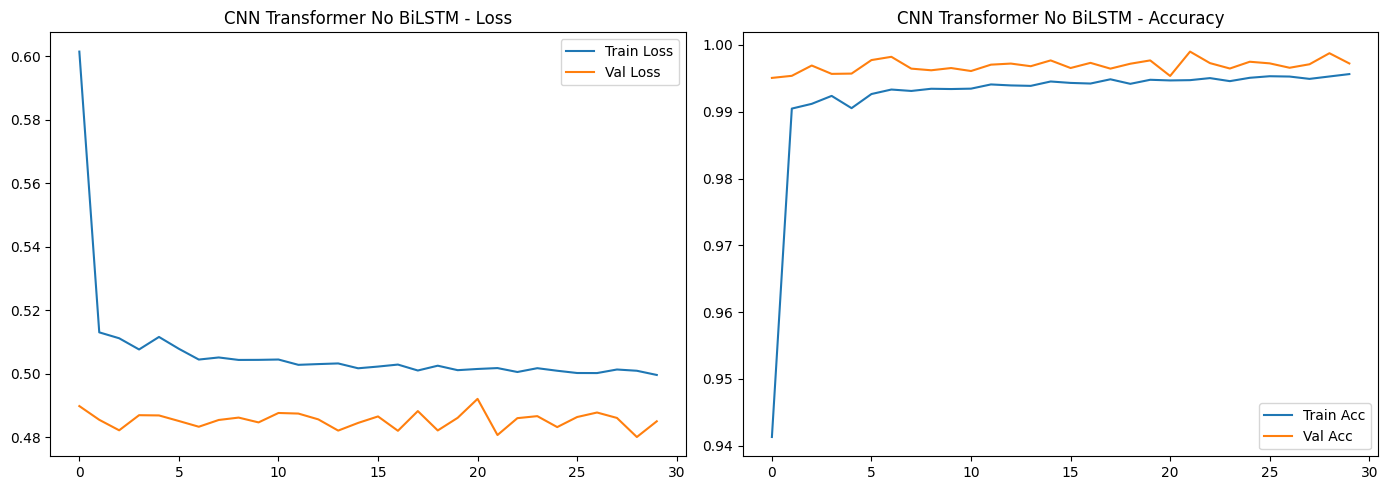

In [15]:
print("Training CNN+Transformer (No BiLSTM)...")
history_nb = train_model(model_no_bilstm, train_loader, val_loader,
                          CONFIG['epochs'], save_path='nbaiot_no_bilstm_best.pth')
plot_history(history_nb, "CNN Transformer No BiLSTM")

In [16]:
print("Fitting MinMax Gate for CNN+Transformer (No BiLSTM)...")
train_feats_nb, train_labels_nb = get_prob_features(model_no_bilstm, train_loader, device)
gate_nb = MinMaxThreeWayGate(q=7).fit(train_feats_nb, train_labels_nb)
print(f"Gate fitted | feats: {train_feats_nb.shape}")

Fitting MinMax Gate for CNN+Transformer (No BiLSTM)...
Gate fitted | feats: (1004702, 8)



  EVALUATION: CNN + Transformer (No BiLSTM)

  Total test samples  : 366171
  Predicted Emerging  : 153563 (excluded from metrics)
  Evaluated samples   : 212608

  Accuracy : 1.0000
  Precision: 1.0000
  Recall   : 1.0000
  F1-Score : 1.0000

  Classification Report (Emerging excluded):
                precision    recall  f1-score   support

  Gafgyt_Combo       1.00      1.00      1.00     16658
   Gafgyt_Junk       1.00      1.00      1.00      8318
    Gafgyt_TCP       1.00      1.00      1.00     28047
     Mirai_ACK       1.00      1.00      1.00     32093
     Mirai_SYN       1.00      1.00      1.00     35808
    Mirai_Scan       0.00      0.00      0.00         1
     Mirai_UDP       1.00      1.00      1.00     57086
Mirai_UDPPlain       1.00      1.00      1.00     25373
        benign       1.00      1.00      1.00      9224

      accuracy                           1.00    212608
     macro avg       0.89      0.89      0.89    212608
  weighted avg       1.00      1.00 

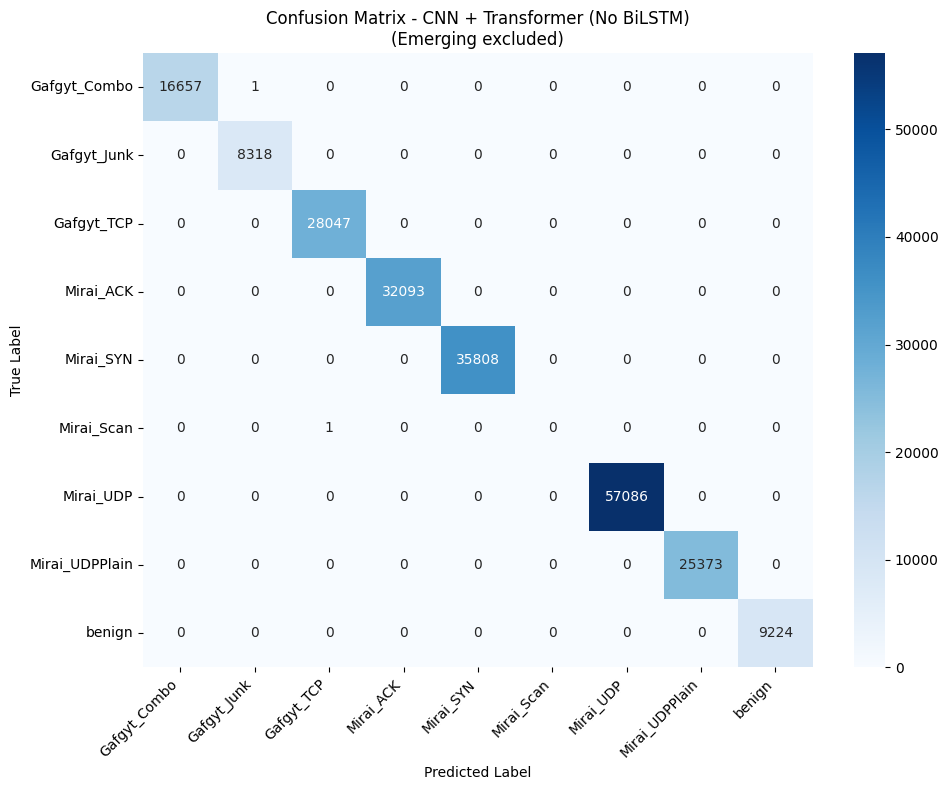

In [17]:
results_nb = evaluate_model(model_no_bilstm, test_loader, gate_nb, le,
                             y_test_final_str, "CNN + Transformer (No BiLSTM)")